# 実験1 (`ex001`): EPIC — 事前学習済み画像分類ネットワークのプロトタイプベース説明手法の再現実験

本ノートブックでは，AAAI 2026 採択論文 **「EPIC: Explanation of Pretrained Image Classification Networks via Prototypes」**（Borycki et al., 2026）の再現実験を行う．

## 実験項目
1. **Disentanglement Module の学習動態と変換行列制約（直交行列 vs. 一般可逆行列）の比較**
2. **Purity（純度）分布の変化とプロトタイプ画素ベクトルの分離可視化（論文 Figure 4 の再現）**
3. **複数バックボーン（ResNet-18 / ResNet-34 / ResNet-50 / DenseNet-121）における予測完全保存性と Purity 向上の検証（Remark 3.1・論文 Table 1 の再現）**
4. **EPIC 適用前後のチャネルプロトタイプ群の視覚的一貫性比較（論文 Figure 3 の再現）**
5. **Algorithm 1（上位寄与チャネル選出）による判断根拠説明と Grad-CAM との比較（論文 Figure 1, 5 の再現）**
6. **正寄与度カバー率および画素空間 Deletion / Insertion テストによる説明忠実度（Faithfulness）の定量評価**

---

In [1]:
import os
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision

from model import build_pretrained_backbone_and_head, EPICModel
from utils import (
    setup_japanese_matplotlib,
    load_imagenette_datasets,
    extract_backbone_features,
    compute_all_channel_purities,
    train_epic_disentanglement,
    evaluate_prediction_equivalence,
    find_activation_bbox,
    draw_yellow_box,
    compute_gradcam,
    evaluate_channel_concentration_and_deletion,
    evaluate_spatial_part_faithfulness,
    IMAGENETTE_CLASS_NAMES_EN,
    IMAGENETTE_CLASS_NAMES_JA,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
setup_japanese_matplotlib()

IMG_DIR = Path("../report/img")
IMG_DIR.mkdir(parents=True, exist_ok=True)
DATASET_ROOT = Path("../datasets")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch          : {torch.__version__}, Torchvision: {torchvision.__version__}")
print(f"使用デバイス     : {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

train_norm, val_norm, train_vis, val_vis, imagenet1k_indices = load_imagenette_datasets(DATASET_ROOT)
imagenet_categories = torchvision.models.ResNet34_Weights.IMAGENET1K_V1.meta["categories"]
print(f"Imagenette 訓練枚数: {len(train_norm)}, 検証枚数: {len(val_norm)}")
print("対象10クラス対応:", [(i, IMAGENETTE_CLASS_NAMES_EN[i], imagenet1k_indices[i]) for i in range(10)])

PyTorch          : 2.7.1+cu118, Torchvision: 0.22.1+cu118
使用デバイス     : cuda (NVIDIA GeForce RTX 4080)
Imagenette 訓練枚数: 9469, 検証枚数: 3925
対象10クラス対応: [(0, 'tench', 0), (1, 'English springer', 217), (2, 'cassette player', 482), (3, 'chain saw', 491), (4, 'church', 497), (5, 'French horn', 566), (6, 'garbage truck', 569), (7, 'gas pump', 571), (8, 'golf ball', 574), (9, 'parachute', 701)]


## 1. Disentanglement Module の学習動態と直交行列・可逆行列の比較（ResNet-34）

論文 3節「Training」（p.5）の設定に従い，凍結した事前学習済み `ResNet-34`（ $D = 512$ ）の最終層直前に `DisentanglementModule` を挿入し，以下の条件で20エポック最適化する：
- プロトタイプ再計算間隔：2エポックごと
- チャネルあたりのプロトタイプ枚数 $m$ ：初期 $m = 100$ から終了時 $m = 5$ まで線形減少
- 最適化手法：Adam（ $\beta_1 = 0.9$ ， $\beta_2 = 0.999$ ，学習率 $0.001$ ，重み減衰 $10^{-5}$ ，バッチサイズ $512$ ）
- 変換行列 $U \in \mathbb{R}^{D \times D}$ のクラス：`orthogonal`（直交行列）および `invertible`（一般の可逆行列）の双方を比較

---

特徴マップ形状: (9469, 512, 7, 7), 抽出時間: 19.96秒


EPIC学習 (invertible, D=512): 100%|##########| 20/20 [00:03<00:00,  6.59it/s, m=5, loss=0.2852, purity(m=5)=0.7162]


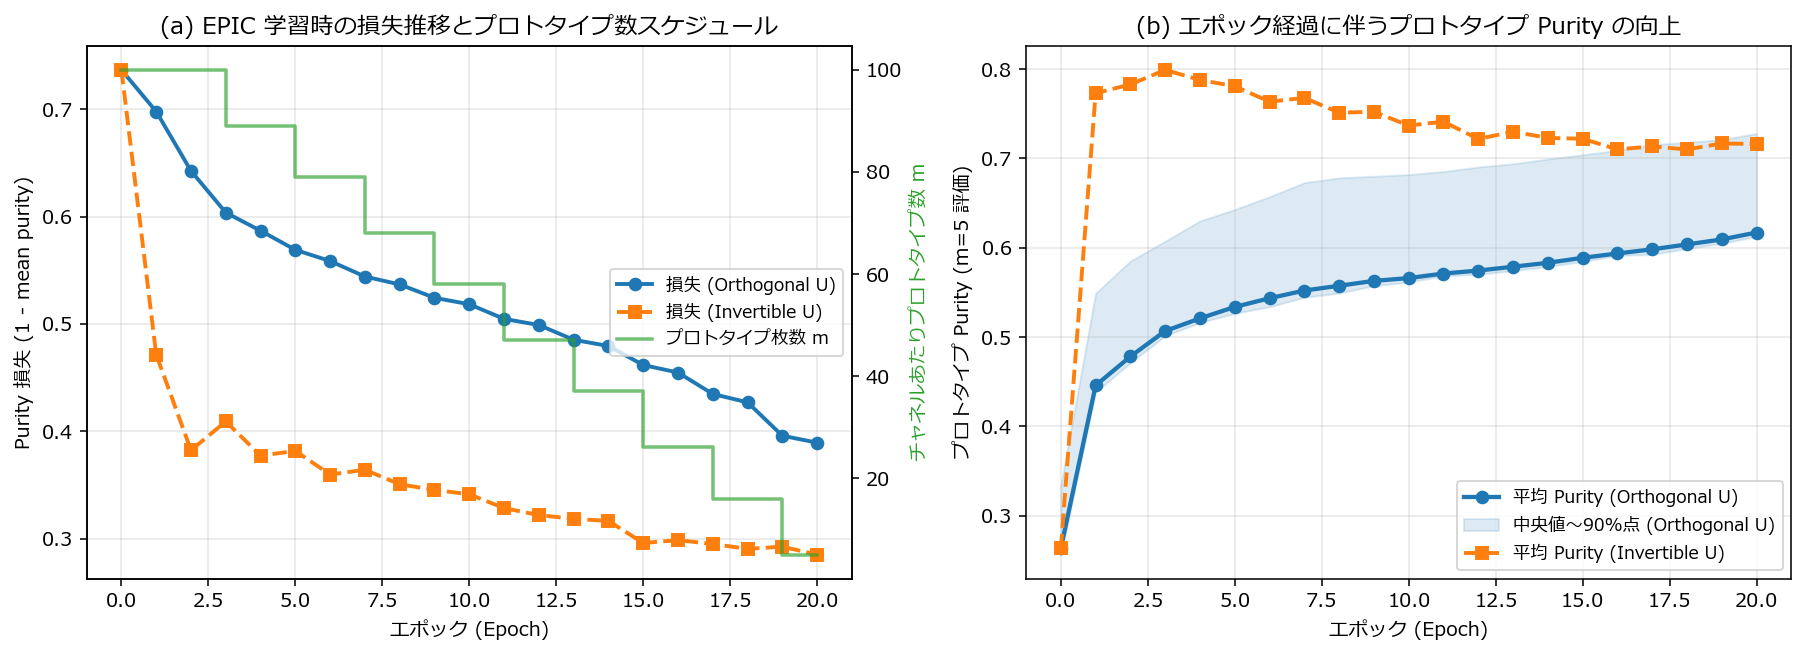

,epoch,m_prototypes,loss,mean_purity_m5,median_purity_m5,p90_purity_m5
0,0,100,0.7365,0.2635,0.2565,0.3341
2,2,100,0.6425,0.4783,0.4714,0.5852
6,6,79,0.5585,0.5435,0.5340,0.6571
10,10,58,0.5184,0.5661,0.5617,0.6820
14,14,37,0.4795,0.5832,0.5791,0.6994
18,18,16,0.4270,0.6038,0.5991,0.7179
20,20,5,0.3895,0.6171,0.6126,0.7279


In [2]:
# ResNet-34 の特徴マップ Z ∈ R^{N×512×7×7} を事前抽出
backbone_r34, base_r34, fc_r34, dim_r34 = build_pretrained_backbone_and_head("resnet34")
backbone_r34.to(device)

t0 = time.time()
z_train_r34, y_train_r34 = extract_backbone_features(
    backbone_r34, train_norm, device=device, batch_size=256, dtype=torch.float32, desc="ResNet-34 訓練特徴抽出"
)
print(f"特徴マップ形状: {tuple(z_train_r34.shape)}, 抽出時間: {time.time() - t0:.2f}秒")

# (A) 直交行列制約 (orthogonal) での EPIC 学習
epic_r34_ortho = EPICModel(backbone_r34, fc_r34, matrix_type="orthogonal")
hist_ortho = train_epic_disentanglement(
    epic_r34_ortho, z_train_r34, device=device, epochs=20, seed=42, track_purity_every_epoch=True
)

# (B) 一般可逆行列 (invertible) での EPIC 学習
epic_r34_inv = EPICModel(backbone_r34, fc_r34, matrix_type="invertible")
hist_inv = train_epic_disentanglement(
    epic_r34_inv, z_train_r34, device=device, epochs=20, seed=42, track_purity_every_epoch=True
)

# 学習曲線の可視化
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax1 = axes[0]
ax1_sub = ax1.twinx()
l1 = ax1.plot(hist_ortho["epoch"], hist_ortho["loss"], "o-", color="#1f77b4", lw=2, label="損失 (Orthogonal U)")
l2 = ax1.plot(hist_inv["epoch"], hist_inv["loss"], "s--", color="#ff7f0e", lw=2, label="損失 (Invertible U)")
l3 = ax1_sub.step(hist_ortho["epoch"], hist_ortho["m_prototypes"], where="post", color="#2ca02c", alpha=0.65, lw=1.8, label="プロトタイプ枚数 m")
ax1.set_xlabel("エポック (Epoch)")
ax1.set_ylabel("Purity 損失 (1 - mean purity)")
ax1_sub.set_ylabel("チャネルあたりプロトタイプ数 m", color="#2ca02c")
ax1.set_title("(a) EPIC 学習時の損失推移とプロトタイプ数スケジュール")
ax1.grid(True, alpha=0.3)
lines = l1 + l2 + l3
ax1.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=9)

ax2 = axes[1]
ax2.plot(hist_ortho["epoch"], hist_ortho["mean_purity_m5"], "o-", color="#1f77b4", lw=2.2, label="平均 Purity (Orthogonal U)")
ax2.fill_between(
    hist_ortho["epoch"], hist_ortho["median_purity_m5"], hist_ortho["p90_purity_m5"],
    color="#1f77b4", alpha=0.15, label="中央値〜90%点 (Orthogonal U)"
)
ax2.plot(hist_inv["epoch"], hist_inv["mean_purity_m5"], "s--", color="#ff7f0e", lw=2.0, label="平均 Purity (Invertible U)")
ax2.set_xlabel("エポック (Epoch)")
ax2.set_ylabel("プロトタイプ Purity (m=5 評価)")
ax2.set_title("(b) エポック経過に伴うプロトタイプ Purity の向上")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex001_training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

hist_ortho.iloc[[0, 2, 6, 10, 14, 18, 20]].round(4)

## 2. Purity 分布の変化とプロトタイプ画素ベクトルの分離（論文 Figure 4 の再現）

EPIC 適用前（ $U = I_{512}$ ）と適用後（Orthogonal $U$ / Invertible $U$ ）における全512チャネルの Purity 分布を比較する．また，特定チャネルのプロトタイプ画像における最大活性化位置 $(h^{\ast}, w^{\ast})$ の画素特徴ベクトル $p \in \mathbb{R}_{\geq 0}^{512}$ の分布を可視化し，論文 Figure 4 で示された「平坦で複数チャネルが混在した活性化から，単一チャネルが支配的な分離表現への変換」を検証する．

---

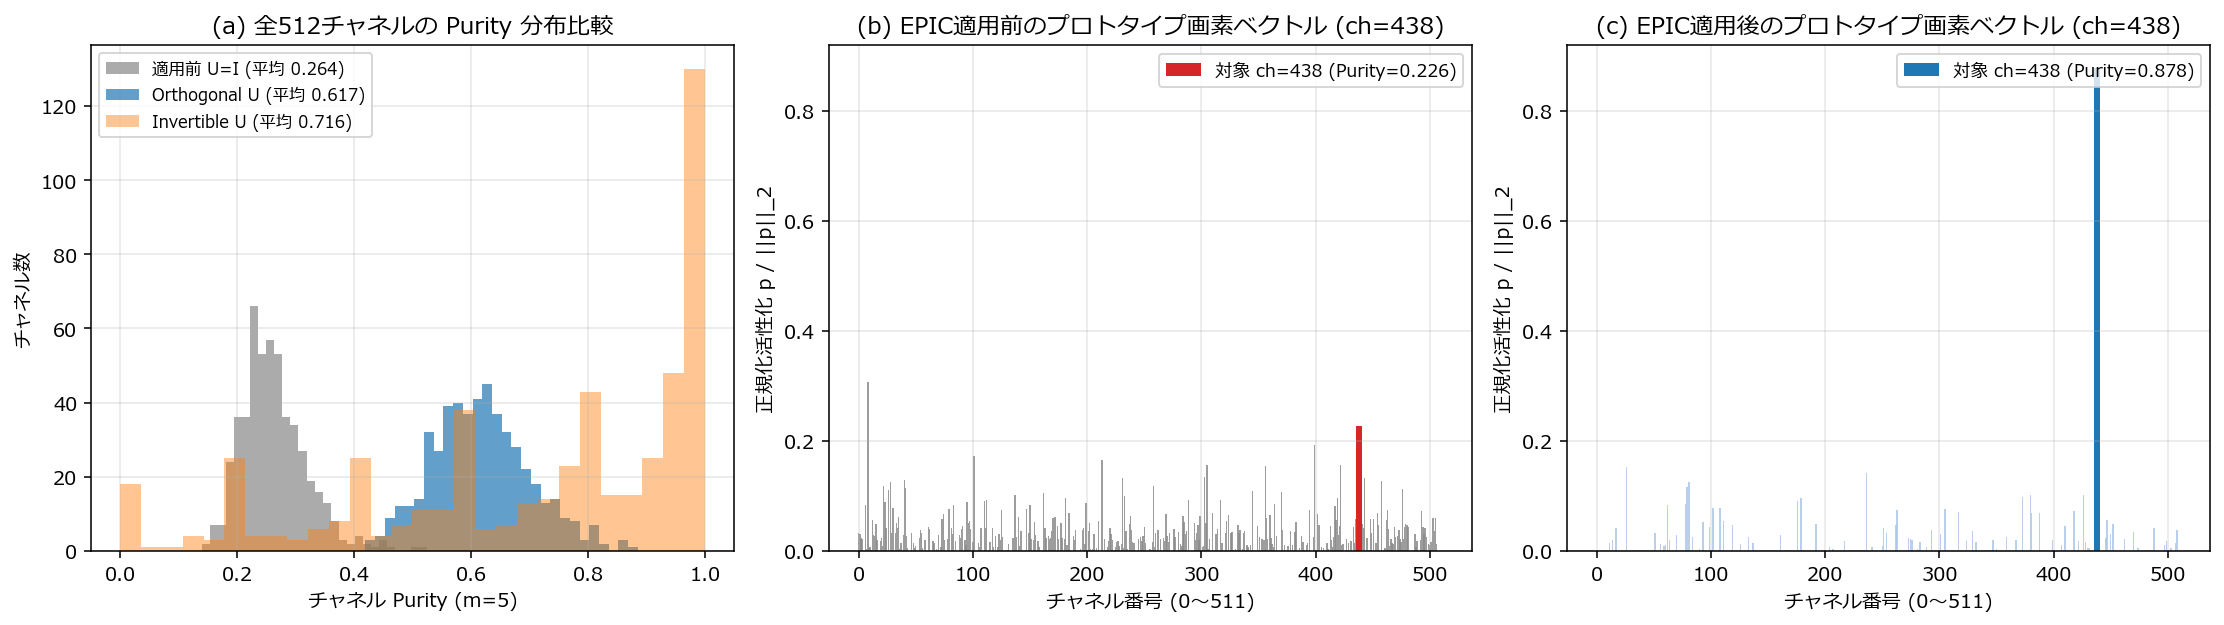

,設定,平均Purity,標準偏差,最小Purity,中央値Purity,最大Purity,Purity>=0.50比率(%),Purity>=0.60比率(%),死滅チャネル数(<0.05)
0,EPIC適用前 (U = I),0.2635,0.0559,0.1401,0.2565,0.5251,0.1953,0.0000,0
1,EPIC適用後 (Orthogonal U),0.6171,0.0832,0.4196,0.6126,0.8854,92.5781,56.4453,0
2,EPIC適用後 (Invertible U),0.7162,0.2859,0.0000,0.7999,1.0000,77.9297,69.9219,19


In [3]:
U_identity = torch.eye(dim_r34, device=device)
pur_before, proto_idx_before = compute_all_channel_purities(z_train_r34, U_identity, m_proto=5, device=device)
pur_ortho, proto_idx_ortho = compute_all_channel_purities(
    z_train_r34, epic_r34_ortho.disentangle.get_matrix(), m_proto=5, device=device
)
pur_inv, proto_idx_inv = compute_all_channel_purities(
    z_train_r34, epic_r34_inv.disentangle.get_matrix(), m_proto=5, device=device
)

summary_purity_df = pd.DataFrame(
    [
        {
            "設定": "EPIC適用前 (U = I)",
            "平均Purity": float(pur_before.mean()),
            "標準偏差": float(pur_before.std()),
            "最小Purity": float(pur_before.min()),
            "中央値Purity": float(pur_before.median()),
            "最大Purity": float(pur_before.max()),
            "Purity>=0.50比率(%)": float((pur_before >= 0.50).float().mean() * 100),
            "Purity>=0.60比率(%)": float((pur_before >= 0.60).float().mean() * 100),
            "死滅チャネル数(<0.05)": int((pur_before < 0.05).sum()),
        },
        {
            "設定": "EPIC適用後 (Orthogonal U)",
            "平均Purity": float(pur_ortho.mean()),
            "標準偏差": float(pur_ortho.std()),
            "最小Purity": float(pur_ortho.min()),
            "中央値Purity": float(pur_ortho.median()),
            "最大Purity": float(pur_ortho.max()),
            "Purity>=0.50比率(%)": float((pur_ortho >= 0.50).float().mean() * 100),
            "Purity>=0.60比率(%)": float((pur_ortho >= 0.60).float().mean() * 100),
            "死滅チャネル数(<0.05)": int((pur_ortho < 0.05).sum()),
        },
        {
            "設定": "EPIC適用後 (Invertible U)",
            "平均Purity": float(pur_inv.mean()),
            "標準偏差": float(pur_inv.std()),
            "最小Purity": float(pur_inv.min()),
            "中央値Purity": float(pur_inv.median()),
            "最大Purity": float(pur_inv.max()),
            "Purity>=0.50比率(%)": float((pur_inv >= 0.50).float().mean() * 100),
            "Purity>=0.60比率(%)": float((pur_inv >= 0.60).float().mean() * 100),
            "死滅チャネル数(<0.05)": int((pur_inv < 0.05).sum()),
        },
    ]
)

# 論文 Figure 4 の再現：EPIC適用後に大きく Purity が向上した代表チャネルのプロトタイプ画素ベクトルを比較
purity_gain = pur_ortho - pur_before
sample_ch = int(purity_gain.argmax().item())
img_id_before = int(proto_idx_before[0, sample_ch].item())
img_id_after = int(proto_idx_ortho[0, sample_ch].item())

with torch.no_grad():
    z_b_map = z_train_r34[img_id_before]  # (512, 7, 7)
    pos_b = int(z_b_map[sample_ch].reshape(-1).argmax().item())
    vec_before = torch.relu(z_b_map.reshape(dim_r34, -1)[:, pos_b])
    vec_before_norm = (vec_before / vec_before.norm()).numpy()

    U_opt = epic_r34_ortho.disentangle.get_matrix().detach().cpu()
    z_a_map = torch.einsum("dc,chw->dhw", U_opt, z_train_r34[img_id_after])
    pos_a = int(z_a_map[sample_ch].reshape(-1).argmax().item())
    vec_after = torch.relu(z_a_map.reshape(dim_r34, -1)[:, pos_a])
    vec_after_norm = (vec_after / vec_after.norm()).numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

axes[0].hist(pur_before.numpy(), bins=28, alpha=0.65, color="#7f7f7f", label=f"適用前 U=I (平均 {pur_before.mean():.3f})")
axes[0].hist(pur_ortho.numpy(), bins=28, alpha=0.70, color="#1f77b4", label=f"Orthogonal U (平均 {pur_ortho.mean():.3f})")
axes[0].hist(pur_inv.numpy(), bins=28, alpha=0.45, color="#ff7f0e", label=f"Invertible U (平均 {pur_inv.mean():.3f})")
axes[0].set_xlabel("チャネル Purity (m=5)")
axes[0].set_ylabel("チャネル数")
axes[0].set_title("(a) 全512チャネルの Purity 分布比較")
axes[0].legend(fontsize=8.5)
axes[0].grid(True, alpha=0.3)

axes[1].bar(np.arange(dim_r34), vec_before_norm, width=1.2, color="#8c8c8c", alpha=0.85)
axes[1].bar([sample_ch], [vec_before_norm[sample_ch]], width=5.0, color="#d62728", label=f"対象 ch={sample_ch} (Purity={vec_before_norm[sample_ch]:.3f})")
axes[1].set_ylim(0, 0.92)
axes[1].set_xlabel("チャネル番号 (0〜511)")
axes[1].set_ylabel("正規化活性化 p / ||p||_2")
axes[1].set_title(f"(b) EPIC適用前のプロトタイプ画素ベクトル (ch={sample_ch})")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(True, alpha=0.3)

axes[2].bar(np.arange(dim_r34), vec_after_norm, width=1.2, color="#aec7e8", alpha=0.85)
axes[2].bar([sample_ch], [vec_after_norm[sample_ch]], width=5.0, color="#1f77b4", label=f"対象 ch={sample_ch} (Purity={vec_after_norm[sample_ch]:.3f})")
axes[2].set_ylim(0, 0.92)
axes[2].set_xlabel("チャネル番号 (0〜511)")
axes[2].set_ylabel("正規化活性化 p / ||p||_2")
axes[2].set_title(f"(c) EPIC適用後のプロトタイプ画素ベクトル (ch={sample_ch})")
axes[2].legend(loc="upper right", fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex001_purity_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

summary_purity_df.round(4)

## 3. 複数バックボーンにおける予測完全保存性と Purity 向上の検証（Remark 3.1・論文 Table 1）

論文 Remark 3.1 により，任意の可逆行列 $U$ に対して次式が成立する：

$$
U^{-1} \,\mathrm{AvgPool}(U \circledast Z) = \mathrm{AvgPool}(Z)
$$

したがって，分類層の重みを $A' = A U^{-1}$ と置き換えた EPIC モデルは元の事前学習済みモデルの予測ロジット・分類精度を一切損なわない．
ここでは `ResNet-18`, `ResNet-34`, `DenseNet-121`, `ResNet-50` の4種類の事前学習済みネットワーク（および ResNet-34 の Invertible 行列版）について，浮動小数点演算における数値誤差・予測一致率・分類精度・Purity 向上幅を一括検証する．

---


=== 評価中: ResNet-18 (Orthogonal) ===

=== 評価中: ResNet-34 (Orthogonal) ===

=== 評価中: ResNet-34 (Invertible) ===

=== 評価中: DenseNet-121 (Orthogonal) ===

=== 評価中: ResNet-50 (Orthogonal) ===


EPIC学習 (orthogonal, D=2048): 100%|##########| 20/20 [01:53<00:00,  5.70s/it, m=5, loss=0.4640, purity(m=5)=0.5543]


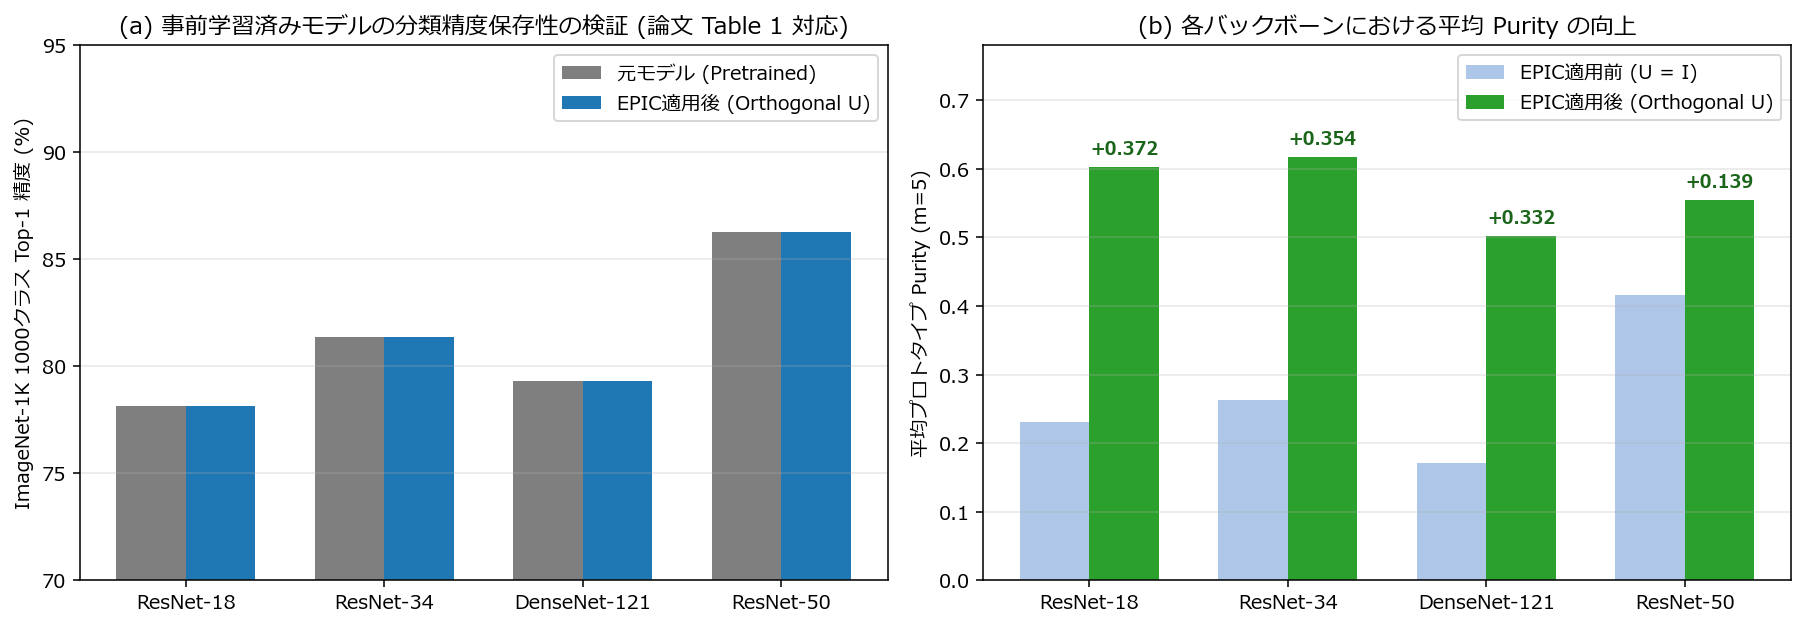

,モデル,チャネル数 D,Purity(前),Purity(後),Purity向上幅,ImageNet1K Top-1(前)%,ImageNet1K Top-1(後)%,Imagenette10 精度(前)%,Imagenette10 精度(後)%,予測一致率(%),最大ロジット誤差,条件数 cond(U)
0,ResNet-18 (Orthogonal),512,0.2304,0.6028,0.3723,78.14,78.14,99.03,99.03,100.0,0.000023,1.0003
1,ResNet-34 (Orthogonal),512,0.2635,0.6171,0.3536,81.35,81.35,99.26,99.26,100.0,0.000025,1.0003
2,ResNet-34 (Invertible),512,0.2635,0.7162,0.4527,81.35,81.35,99.26,99.26,100.0,0.000124,150.6053
3,DenseNet-121 (Orthogonal),1024,0.1704,0.5021,0.3317,79.31,79.31,99.36,99.36,100.0,0.000027,1.0003
4,ResNet-50 (Orthogonal),2048,0.4153,0.5543,0.1390,86.29,86.29,99.77,99.77,100.0,0.000009,1.0008


In [4]:
arch_configs = [
    ("ResNet-18 (Orthogonal)", "resnet18", "orthogonal", torch.float32),
    ("ResNet-34 (Orthogonal)", "resnet34", "orthogonal", torch.float32),
    ("ResNet-34 (Invertible)", "resnet34", "invertible", torch.float32),
    ("DenseNet-121 (Orthogonal)", "densenet121", "orthogonal", torch.float16),
    ("ResNet-50 (Orthogonal)", "resnet50", "orthogonal", torch.float16),
]

backbone_records = []
trained_models_cache = {
    "resnet34_orthogonal": epic_r34_ortho,
    "resnet34_invertible": epic_r34_inv,
}

for disp_name, arch_key, mat_type, feat_dtype in arch_configs:
    print(f"\n=== 評価中: {disp_name} ===")
    bb, base_m, fc_m, d_ch = build_pretrained_backbone_and_head(arch_key)
    bb.to(device)

    if arch_key == "resnet34":
        z_tr = z_train_r34
        epic_m = trained_models_cache[f"resnet34_{mat_type}"]
    else:
        z_tr, _ = extract_backbone_features(
            bb, train_norm, device=device, batch_size=256, dtype=feat_dtype, desc=f"{arch_key} 特徴抽出"
        )
        epic_m = EPICModel(bb, fc_m, matrix_type=mat_type)
        _ = train_epic_disentanglement(
            epic_m, z_tr, device=device, epochs=20, seed=42, track_purity_every_epoch=False
        )

    pur_b, _ = compute_all_channel_purities(z_tr, torch.eye(d_ch, device=device), m_proto=5, device=device)
    pur_a, _ = compute_all_channel_purities(z_tr, epic_m.disentangle.get_matrix(), m_proto=5, device=device)
    eq_metrics = evaluate_prediction_equivalence(base_m, epic_m, val_norm, imagenet1k_indices, device=device)

    rec = {
        "モデル": disp_name,
        "チャネル数 D": d_ch,
        "Purity(前)": round(float(pur_b.mean()), 4),
        "Purity(後)": round(float(pur_a.mean()), 4),
        "Purity向上幅": round(float(pur_a.mean() - pur_b.mean()), 4),
        "ImageNet1K Top-1(前)%": round(eq_metrics["Base_ImageNet1K_Top1(%)"], 2),
        "ImageNet1K Top-1(後)%": round(eq_metrics["EPIC_ImageNet1K_Top1(%)"], 2),
        "Imagenette10 精度(前)%": round(eq_metrics["Base_Imagenette10_Acc(%)"], 2),
        "Imagenette10 精度(後)%": round(eq_metrics["EPIC_Imagenette10_Acc(%)"], 2),
        "予測一致率(%)": round(eq_metrics["Prediction_Agreement(%)"], 2),
        "最大ロジット誤差": eq_metrics["Max_Abs_Logit_Diff"],
        "条件数 cond(U)": round(eq_metrics["Cond_U"], 4),
    }
    backbone_records.append(rec)

    if arch_key in ("resnet18", "resnet50", "densenet121"):
        del z_tr, epic_m, bb, base_m
        torch.cuda.empty_cache()

backbone_df = pd.DataFrame(backbone_records)

ortho_df = backbone_df[backbone_df["モデル"].str.contains("Orthogonal")].reset_index(drop=True)
short_labels = [s.replace(" (Orthogonal)", "") for s in ortho_df["モデル"]]
x_pos = np.arange(len(short_labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
w = 0.35

axes[0].bar(x_pos - w / 2, ortho_df["ImageNet1K Top-1(前)%"], width=w, color="#7f7f7f", label="元モデル (Pretrained)")
axes[0].bar(x_pos + w / 2, ortho_df["ImageNet1K Top-1(後)%"], width=w, color="#1f77b4", label="EPIC適用後 (Orthogonal U)")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(short_labels)
axes[0].set_ylim(70, 95)
axes[0].set_ylabel("ImageNet-1K 1000クラス Top-1 精度 (%)")
axes[0].set_title("(a) 事前学習済みモデルの分類精度保存性の検証 (論文 Table 1 対応)")
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(x_pos - w / 2, ortho_df["Purity(前)"], width=w, color="#aec7e8", label="EPIC適用前 (U = I)")
axes[1].bar(x_pos + w / 2, ortho_df["Purity(後)"], width=w, color="#2ca02c", label="EPIC適用後 (Orthogonal U)")
for i, (vb, va) in enumerate(zip(ortho_df["Purity(前)"], ortho_df["Purity(後)"])):
    axes[1].text(i + w / 2, va + 0.012, f"+{va - vb:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1b661b")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(short_labels)
axes[1].set_ylim(0, 0.78)
axes[1].set_ylabel("平均プロトタイプ Purity (m=5)")
axes[1].set_title("(b) 各バックボーンにおける平均 Purity の向上")
axes[1].legend()
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(IMG_DIR / "ex001_backbone_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

backbone_df

## 4. EPIC 適用前後のプロトタイプ視覚的一貫性の比較（論文 Figure 3 の再現）

論文 Figure 3 と同様に，最適化前（左： $U = I$ ）と EPIC 最適化後（右：学習済み直交行列 $U$ ）において，同一チャネルの上位 $m = 5$ 枚の正のプロトタイプ画像 $\mathrm{Prot}_{\mathrm{pos}}^{(k)}$ とその活性化領域（黄色枠）を比較する．

---

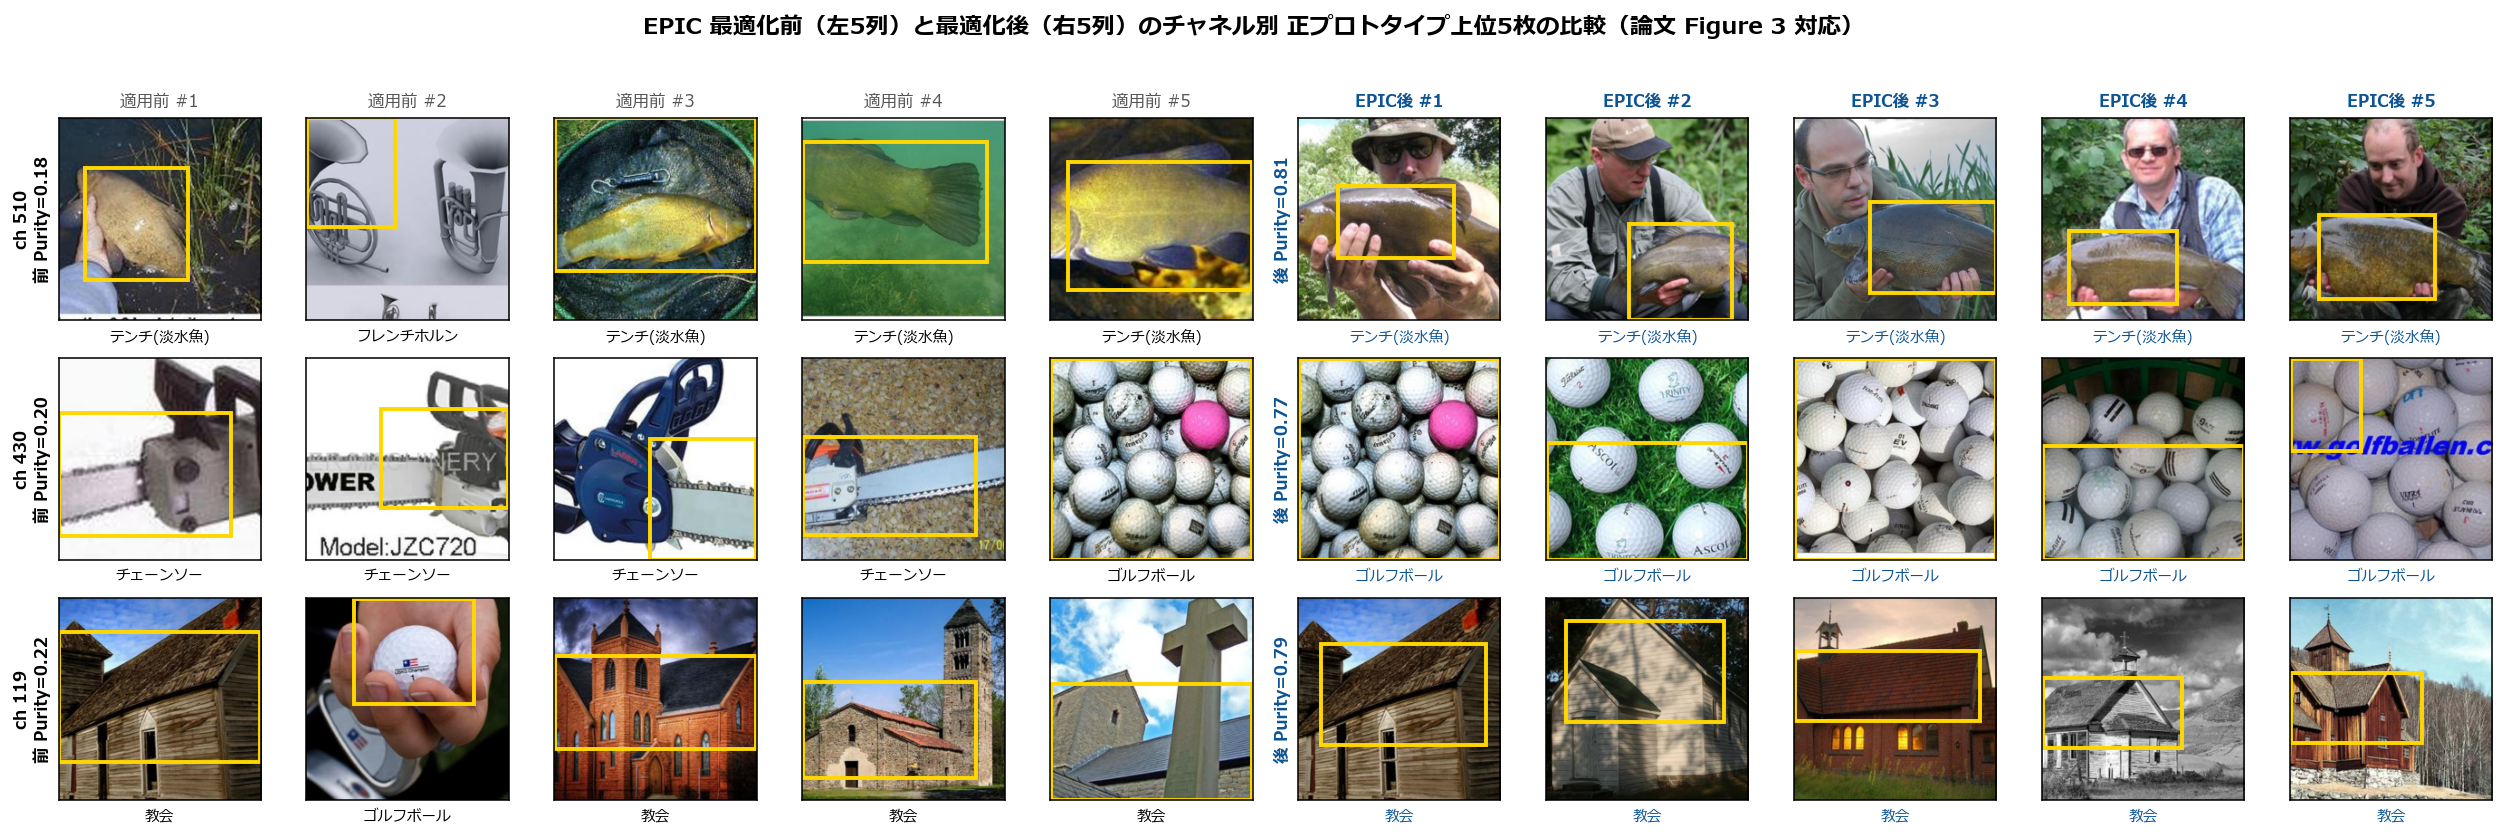

In [5]:
gain_r34 = pur_ortho - pur_before
top_gain_chs = gain_r34.argsort(descending=True)

selected_chs = []
seen_classes = set()
for ch in top_gain_chs.tolist():
    top5_imgs = proto_idx_ortho[:, ch].tolist()
    lbls = [int(y_train_r34[idx].item()) for idx in top5_imgs]
    maj_cls = max(set(lbls), key=lbls.count)
    lbls_before = [int(y_train_r34[idx].item()) for idx in proto_idx_before[:, ch].tolist()]
    if maj_cls not in seen_classes and len(set(lbls_before)) >= 2 and lbls.count(maj_cls) >= 4:
        selected_chs.append(ch)
        seen_classes.add(maj_cls)
    if len(selected_chs) == 3:
        break

U_opt_cpu = epic_r34_ortho.disentangle.get_matrix().detach().cpu()

fig, axes = plt.subplots(len(selected_chs), 10, figsize=(18, 5.8))
for row_i, ch in enumerate(selected_chs):
    for col_j in range(5):
        img_idx = int(proto_idx_before[col_j, ch].item())
        img_vis, lbl = train_vis[img_idx]
        ch_map = z_train_r34[img_idx, ch]
        bbox = find_activation_bbox(ch_map, img_size=224, rel_threshold=0.50)

        ax = axes[row_i, col_j]
        ax.imshow(img_vis.permute(1, 2, 0).numpy())
        draw_yellow_box(ax, bbox, lw=2.0)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(IMAGENETTE_CLASS_NAMES_JA[lbl], fontsize=7.5)
        if col_j == 0:
            ax.set_ylabel(f"ch {ch}\n前 Purity={pur_before[ch]:.2f}", fontsize=8.5, fontweight="bold")
        if row_i == 0:
            ax.set_title(f"適用前 #{col_j+1}", fontsize=8.5, color="#555555")

    for col_j in range(5):
        img_idx = int(proto_idx_ortho[col_j, ch].item())
        img_vis, lbl = train_vis[img_idx]
        z_hat_single = torch.einsum("dc,chw->dhw", U_opt_cpu, z_train_r34[img_idx])
        ch_map = z_hat_single[ch]
        bbox = find_activation_bbox(ch_map, img_size=224, rel_threshold=0.50)

        ax = axes[row_i, 5 + col_j]
        ax.imshow(img_vis.permute(1, 2, 0).numpy())
        draw_yellow_box(ax, bbox, lw=2.0)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(IMAGENETTE_CLASS_NAMES_JA[lbl], fontsize=7.5, color="#0b5394")
        if col_j == 0:
            ax.set_ylabel(f"後 Purity={pur_ortho[ch]:.2f}", fontsize=8.5, fontweight="bold", color="#0b5394")
        if row_i == 0:
            ax.set_title(f"EPIC後 #{col_j+1}", fontsize=8.5, color="#0b5394", fontweight="bold")

fig.suptitle("EPIC 最適化前（左5列）と最適化後（右5列）のチャネル別 正プロトタイプ上位5枚の比較（論文 Figure 3 対応）", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(IMG_DIR / "ex001_prototypes_before_after.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Algorithm 1 による判断根拠のプロトタイプ説明と Grad-CAM との比較（論文 Figure 1, 5 の再現）

検証画像を入力し，論文 Algorithm 1（`TopKChannels`）によって予測クラスへの寄与スコア $s_c = A'[\mathrm{pred}, c] \cdot \mathrm{ReLU}(v_c)$ が上位のチャネルを抽出する．
- 古典的 Post-hoc 手法である **Grad-CAM** は「画像のどこを見たか」を粗いヒートマップで示すにとどまる．
- 一方 **EPIC** は，「入力画像のどの局所パーツ（第1列・黄色枠）が，訓練データ中のどのような概念プロトタイプ群（第2〜6列・黄色枠）と一致したためその予測に至ったか」をパーツ単位で提示できる．

---

選出した検証画像インデックス: [1578, 254]


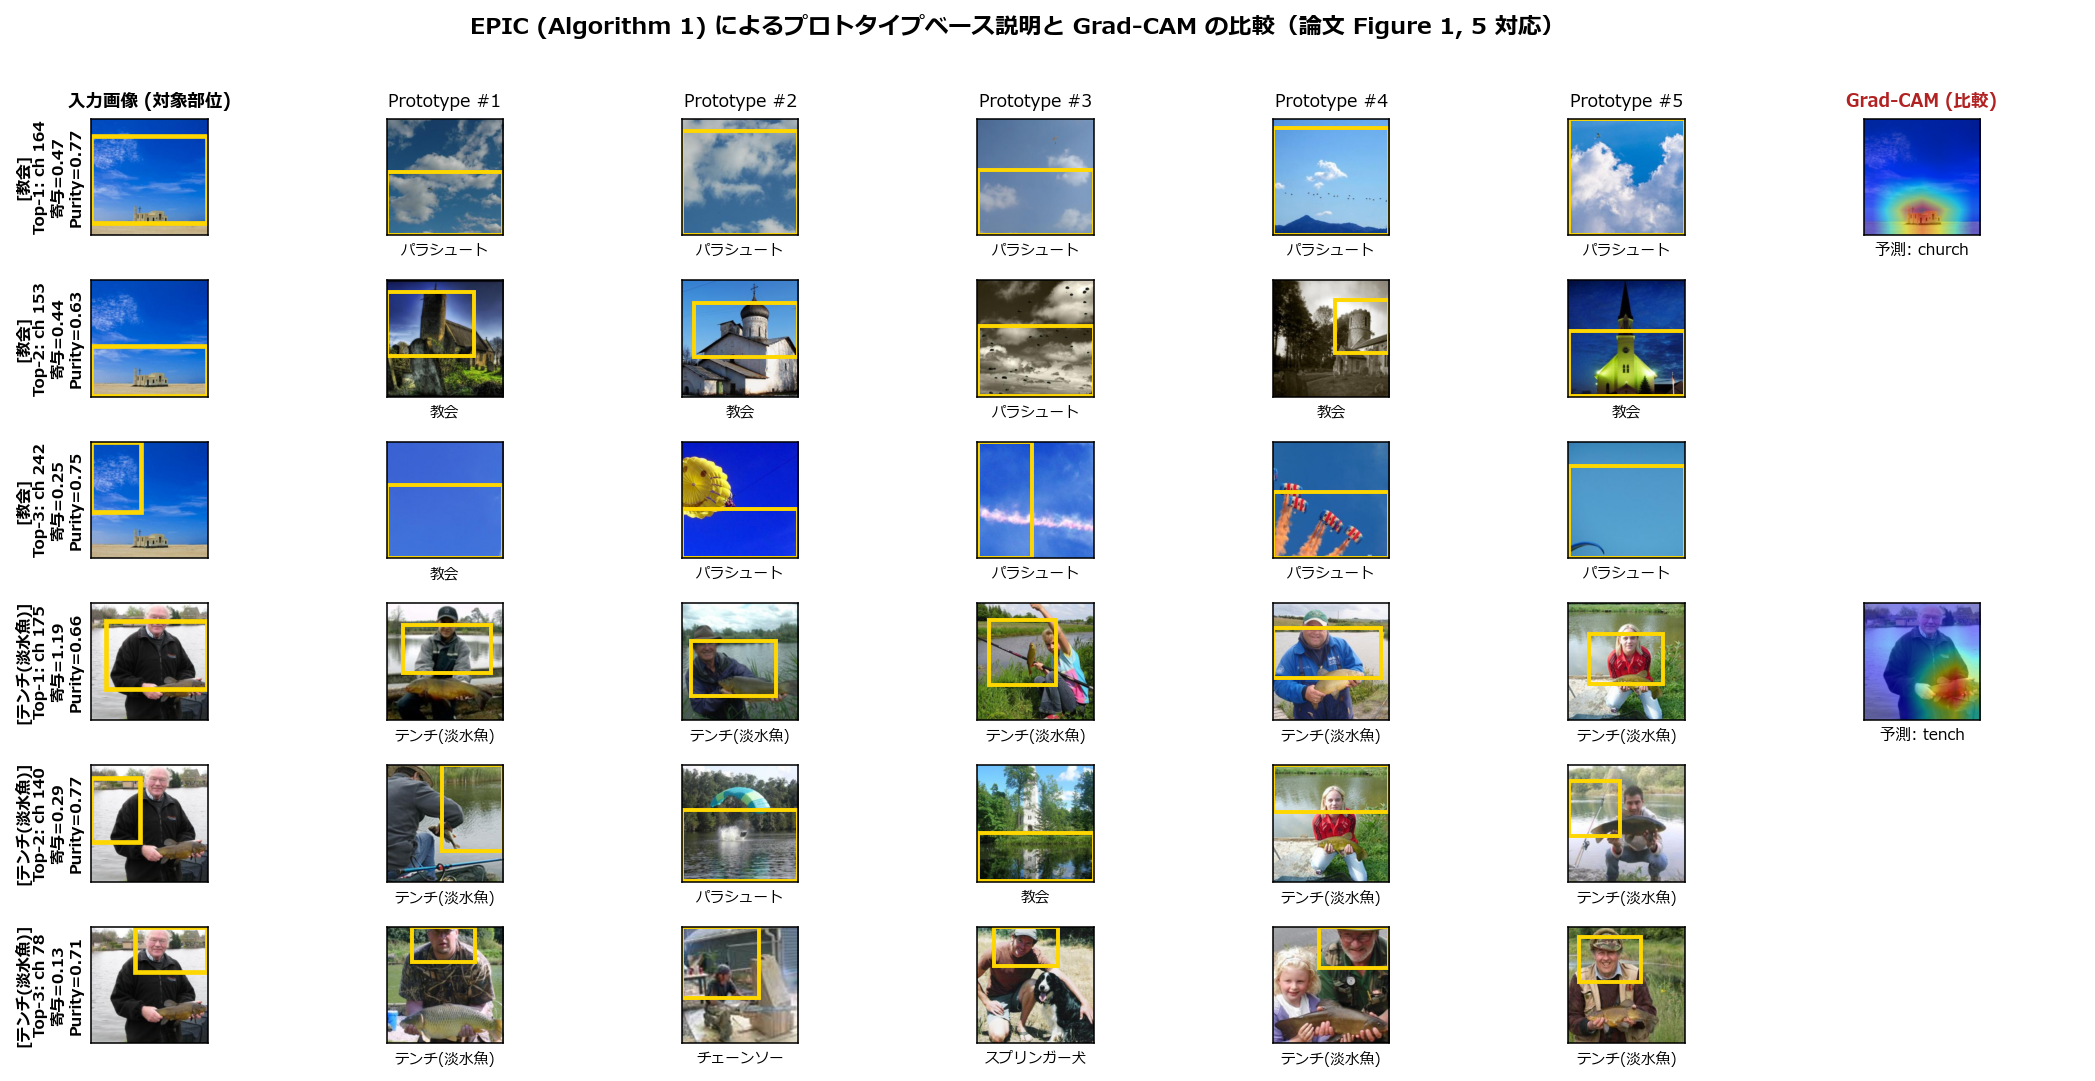

In [6]:
# 検証データから異なる2クラス（教会・テンチ）で正プロトタイプ寄与スコアが高い代表例を選出
target_local_classes = [4, 0]  # 4: church, 0: tench
sample_val_indices = []
for target_c in target_local_classes:
    best_idx, best_score = None, -1.0
    # 該当クラスの検証画像から Top-3 正プロトタイプ寄与和が最も明瞭な1枚を選択
    for idx in range(len(val_norm)):
        if val_norm._samples[idx][1] != target_c:
            continue
        x_item, _ = val_norm[idx]
        top_chs, top_sc, pred_1k, _ = epic_r34_ortho.top_k_contributing_channels(x_item.unsqueeze(0).to(device), k=3)
        if pred_1k == imagenet1k_indices[target_c] and float(top_sc.sum().item()) > best_score:
            best_score = float(top_sc.sum().item())
            best_idx = idx
    sample_val_indices.append(best_idx)

print("選出した検証画像インデックス:", sample_val_indices)

top_k_show = 3
total_rows = len(sample_val_indices) * top_k_show
fig, axes = plt.subplots(total_rows, 7, figsize=(15.5, 3.8 * len(sample_val_indices)))

for ex_i, val_idx in enumerate(sample_val_indices):
    x_in, y_local = val_norm[val_idx]
    img_vis_in, _ = val_vis[val_idx]
    img_np = img_vis_in.permute(1, 2, 0).numpy()

    top_chs, top_scores, pred_1k, z_hat_in = epic_r34_ortho.top_k_contributing_channels(
        x_in.unsqueeze(0).to(device), k=top_k_show
    )
    cam_map, _ = compute_gradcam(backbone_r34, fc_r34, x_in.unsqueeze(0).to(device), target_class=pred_1k)
    pred_name_en = imagenet_categories[pred_1k]
    cls_ja = IMAGENETTE_CLASS_NAMES_JA[y_local]

    for r_k in range(top_k_show):
        row_idx = ex_i * top_k_show + r_k
        ch_id = int(top_chs[r_k].item())
        score_val = float(top_scores[r_k].item())

        ax_in = axes[row_idx, 0]
        ax_in.imshow(img_np)
        bbox_in = find_activation_bbox(z_hat_in[0, ch_id].cpu(), img_size=224, rel_threshold=0.50)
        draw_yellow_box(ax_in, bbox_in, lw=2.4)
        ax_in.set_xticks([])
        ax_in.set_yticks([])
        ax_in.set_ylabel(
            f"[{cls_ja}]\nTop-{r_k+1}: ch {ch_id}\n寄与={score_val:.2f}\nPurity={pur_ortho[ch_id]:.2f}",
            fontsize=8,
            fontweight="bold",
        )
        if row_idx == 0:
            ax_in.set_title("入力画像 (対象部位)", fontsize=9, fontweight="bold")

        for p_j in range(5):
            p_img_idx = int(proto_idx_ortho[p_j, ch_id].item())
            p_vis, p_lbl = train_vis[p_img_idx]
            z_hat_p = torch.einsum("dc,chw->dhw", U_opt_cpu, z_train_r34[p_img_idx])
            bbox_p = find_activation_bbox(z_hat_p[ch_id], img_size=224, rel_threshold=0.50)

            ax_p = axes[row_idx, 1 + p_j]
            ax_p.imshow(p_vis.permute(1, 2, 0).numpy())
            draw_yellow_box(ax_p, bbox_p, lw=2.0)
            ax_p.set_xticks([])
            ax_p.set_yticks([])
            ax_p.set_xlabel(IMAGENETTE_CLASS_NAMES_JA[p_lbl], fontsize=7.5)
            if row_idx == 0:
                ax_p.set_title(f"Prototype #{p_j+1}", fontsize=9)

        ax_cam = axes[row_idx, 6]
        if r_k == 0:
            ax_cam.imshow(img_np)
            ax_cam.imshow(cam_map, cmap="jet", alpha=0.48)
            ax_cam.set_xlabel(f"予測: {pred_name_en}", fontsize=8)
            if row_idx == 0:
                ax_cam.set_title("Grad-CAM (比較)", fontsize=9, fontweight="bold", color="#b22222")
        else:
            ax_cam.axis("off")
        ax_cam.set_xticks([])
        ax_cam.set_yticks([])

fig.suptitle("EPIC (Algorithm 1) によるプロトタイプベース説明と Grad-CAM の比較（論文 Figure 1, 5 対応）", fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(IMG_DIR / "ex001_epic_vs_gradcam.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. 説明忠実度（Faithfulness）の定量評価：少数チャネル寄与集中度と画素空間 Deletion / Insertion テスト

EPIC による特徴分離が説明の簡潔性・因果的忠実度を改善することを2つの観点から定量評価する：
1. **正ロジット寄与カバー率 (%)**：予測クラスへの正寄与 $A'[\mathrm{pred}, c] \cdot \mathrm{ReLU}(v_c)$ の総和のうち，上位 $k$ チャネルのみで何%を説明できるか（EPIC 適用前後比較）
2. **画素空間のパーツ遮蔽・挿入評価（Deletion / Insertion）**：Algorithm 1 で選ばれた上位3プロトタイプチャネルの活性化部位から順に画素を遮蔽（Deletion：低いほど高忠実度）または挿入（Insertion：高いほど高忠実度）した際の予測確信度推移（ランダム遮蔽との比較）

Deletion AUC  (低いほど良好): EPIC Top-3 = 0.2866 vs Random = 0.2337
Insertion AUC (高いほど良好): EPIC Top-3 = 0.3504 vs Random = 0.2299


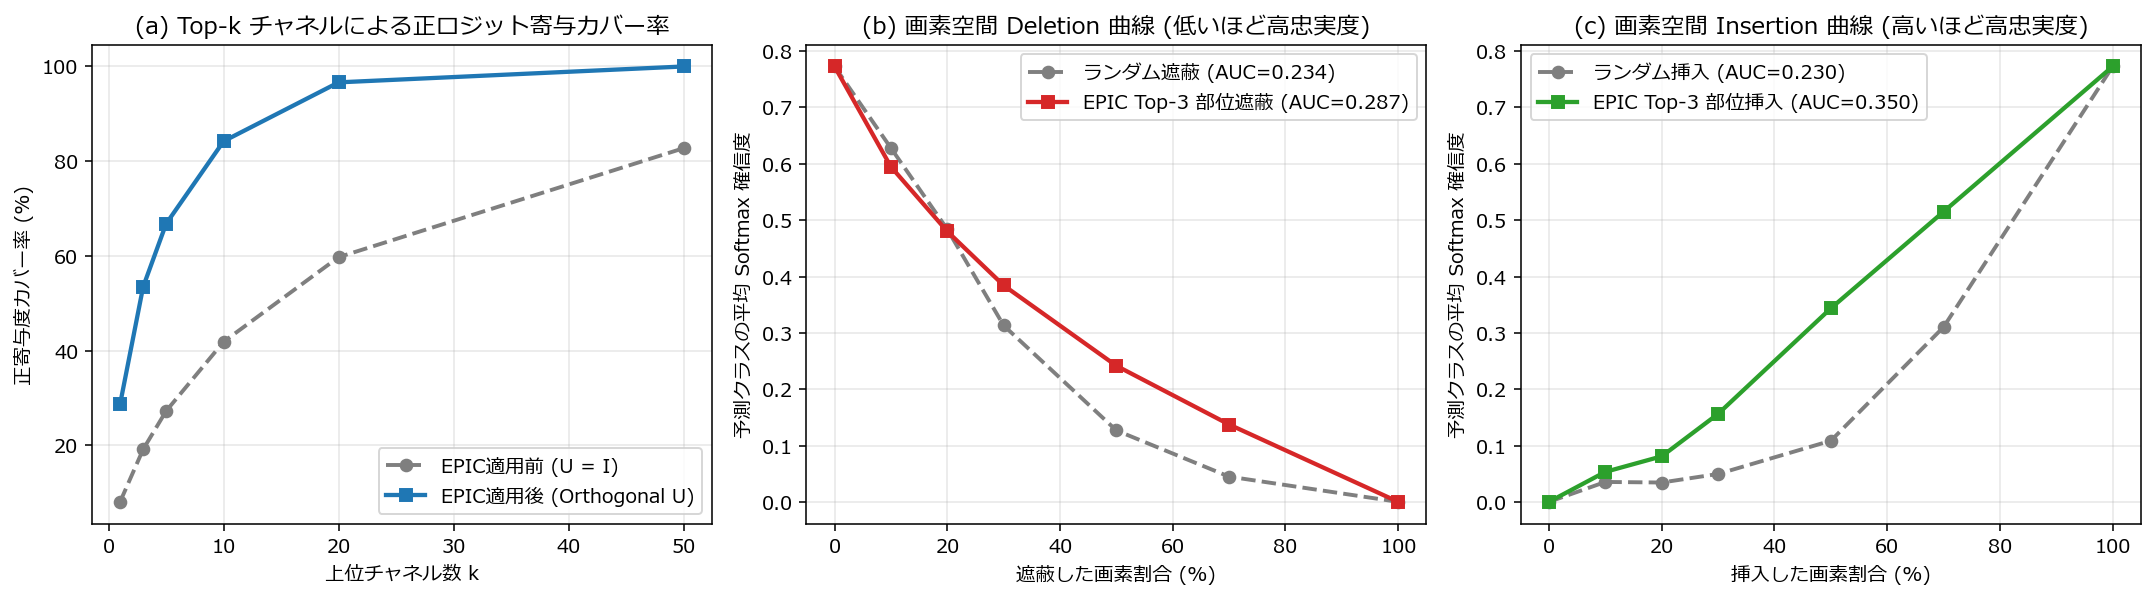

,手法,画素割合(%),Deletion確信度,Insertion確信度
0,EPIC Top-3 プロトタイプ部位,0.0,0.7722,0.0008
1,EPIC Top-3 プロトタイプ部位,10.0,0.5945,0.0539
2,EPIC Top-3 プロトタイプ部位,20.0,0.4800,0.0815
3,EPIC Top-3 プロトタイプ部位,30.0,0.3843,0.1567
4,EPIC Top-3 プロトタイプ部位,50.0,0.2418,0.3437
5,EPIC Top-3 プロトタイプ部位,70.0,0.1378,0.5149
6,EPIC Top-3 プロトタイプ部位,100.0,0.0008,0.7722
7,ランダム領域 (Baseline),0.0,0.7722,0.0008
8,ランダム領域 (Baseline),10.0,0.6276,0.0361
9,ランダム領域 (Baseline),20.0,0.4837,0.0350


In [7]:
epic_r34_identity = EPICModel(backbone_r34, fc_r34, matrix_type="orthogonal")
conc_df = evaluate_channel_concentration_and_deletion(
    epic_r34_identity,
    epic_r34_ortho,
    val_norm,
    device=device,
    max_samples=1000,
    k_list=(1, 3, 5, 10, 20, 50),
)

spatial_df = evaluate_spatial_part_faithfulness(
    base_r34,
    epic_r34_ortho,
    val_norm,
    device=device,
    top_k_channels=3,
    max_samples=256,
    ratios=(0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0),
)

df_c_before = conc_df[conc_df["モデル状態"].str.contains("適用前")]
df_c_after = conc_df[conc_df["モデル状態"].str.contains("適用後")]
df_s_epic = spatial_df[spatial_df["手法"].str.contains("EPIC")]
df_s_rand = spatial_df[spatial_df["手法"].str.contains("ランダム")]

# AUC (台形公式) を算出
auc_del_epic = float(np.trapezoid(df_s_epic["Deletion確信度"], df_s_epic["画素割合(%)"] / 100.0))
auc_del_rand = float(np.trapezoid(df_s_rand["Deletion確信度"], df_s_rand["画素割合(%)"] / 100.0))
auc_ins_epic = float(np.trapezoid(df_s_epic["Insertion確信度"], df_s_epic["画素割合(%)"] / 100.0))
auc_ins_rand = float(np.trapezoid(df_s_rand["Insertion確信度"], df_s_rand["画素割合(%)"] / 100.0))
print(f"Deletion AUC  (低いほど良好): EPIC Top-3 = {auc_del_epic:.4f} vs Random = {auc_del_rand:.4f}")
print(f"Insertion AUC (高いほど良好): EPIC Top-3 = {auc_ins_epic:.4f} vs Random = {auc_ins_rand:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

axes[0].plot(df_c_before["上位チャネル数 k"], df_c_before["正寄与度カバー率(%)"], "o--", color="#7f7f7f", lw=2, label="EPIC適用前 (U = I)")
axes[0].plot(df_c_after["上位チャネル数 k"], df_c_after["正寄与度カバー率(%)"], "s-", color="#1f77b4", lw=2.2, label="EPIC適用後 (Orthogonal U)")
axes[0].set_xlabel("上位チャネル数 k")
axes[0].set_ylabel("正寄与度カバー率 (%)")
axes[0].set_title("(a) Top-k チャネルによる正ロジット寄与カバー率")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(df_s_rand["画素割合(%)"], df_s_rand["Deletion確信度"], "o--", color="#7f7f7f", lw=2, label=f"ランダム遮蔽 (AUC={auc_del_rand:.3f})")
axes[1].plot(df_s_epic["画素割合(%)"], df_s_epic["Deletion確信度"], "s-", color="#d62728", lw=2.2, label=f"EPIC Top-3 部位遮蔽 (AUC={auc_del_epic:.3f})")
axes[1].set_xlabel("遮蔽した画素割合 (%)")
axes[1].set_ylabel("予測クラスの平均 Softmax 確信度")
axes[1].set_title("(b) 画素空間 Deletion 曲線 (低いほど高忠実度)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(df_s_rand["画素割合(%)"], df_s_rand["Insertion確信度"], "o--", color="#7f7f7f", lw=2, label=f"ランダム挿入 (AUC={auc_ins_rand:.3f})")
axes[2].plot(df_s_epic["画素割合(%)"], df_s_epic["Insertion確信度"], "s-", color="#2ca02c", lw=2.2, label=f"EPIC Top-3 部位挿入 (AUC={auc_ins_epic:.3f})")
axes[2].set_xlabel("挿入した画素割合 (%)")
axes[2].set_ylabel("予測クラスの平均 Softmax 確信度")
axes[2].set_title("(c) 画素空間 Insertion 曲線 (高いほど高忠実度)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig(IMG_DIR / "ex001_faithfulness_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

spatial_df.round(4)